# Procesamiento de series temporales

El dataset "ocupacion.csv" describe las medidas ambientales de una habitación con el objetivo de predecir si está ocupada o no.

Hay 20.560 datos medidos con una frecuencia de muestreo de un minuto, tomados a lo largo de unas semanas. El set de datos contiene 7 variables.

**Variables del dataset**
- date: year-month-day hour:minute:second
- Temperature (Temperatura), en Celsius
- Relative Humidity (Humedad relativa) en %
- Light (Luminosidad), en Lux
- CO2, en ppm
- Humidity Ratio (Raio de humedad), derivado de la temperatura y la humedad relativa, en kgwater-vapor/kg-air
- Occupancy, 0 or 1, 0 para habitación NO ocupada, 1 para habitación ocupada

Preparar los datos para su análisis y modelización.

Las credenciales de la fuente de datos pertenecen a Luis Candanedo de UMONS.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("dataset.csv", header=0)

In [3]:
df.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-11 14:48:00,21.7600,31.133333,437.333333,1029.666667,0.005021,1
2,2015-02-11 14:49:00,21.7900,31.000000,437.333333,1000.000000,0.005009,1
3,2015-02-11 14:50:00,21.7675,31.122500,434.000000,1003.750000,0.005022,1
4,2015-02-11 14:51:00,21.7675,31.122500,439.000000,1009.500000,0.005022,1
5,2015-02-11 14:51:59,21.7900,31.133333,437.333333,1005.666667,0.005030,1


In [4]:
df.isna().sum()

date              0
Temperature      44
Humidity          9
Light             8
CO2              23
HumidityRatio    18
Occupancy         0
dtype: int64

In [5]:
df.columns

Index(['date', 'Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio',
       'Occupancy'],
      dtype='str')

<Axes: xlabel='date'>

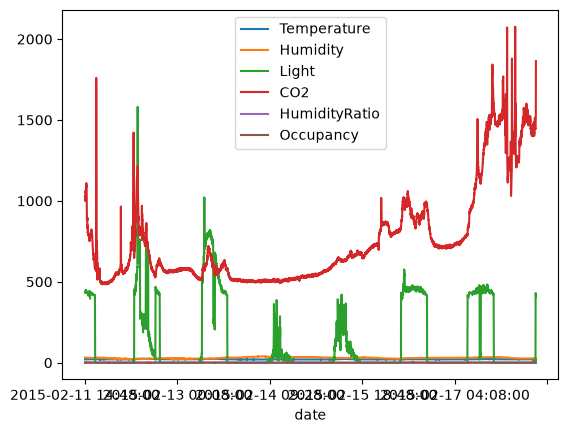

In [6]:
df.set_index('date').plot()

In [7]:
df.dtypes

date                 str
Temperature      float64
Humidity         float64
Light            float64
CO2              float64
HumidityRatio    float64
Occupancy          int64
dtype: object

In [8]:
df['date'] = pd.to_datetime(df['date'])

df = df.sort_values('date')

df['diferencia'] = df['date'].diff()
print(df['diferencia'].value_counts())

diferencia
0 days 00:01:00    5849
0 days 00:00:59    1951
0 days 00:01:01    1951
Name: count, dtype: int64


In [9]:
df = df.drop(columns='diferencia')

df = df.set_index('date')

df = df.resample('1min').mean()

#df = df.interpolate(method='linear')
df['Temperature'] = df['Temperature'].interpolate(method='linear')
df['Humidity'] = df['Humidity'].interpolate(method='linear')
df['Light'] = df['Light'].interpolate(method='linear')
df['CO2'] = df['CO2'].interpolate(method='linear')
df['HumidityRatio'] = df['HumidityRatio'].interpolate(method='linear')

In [10]:
df.isna().sum()

Temperature         0
Humidity            0
Light               0
CO2                 0
HumidityRatio       0
Occupancy        1951
dtype: int64

In [11]:
# o con dropa seria suficiente
#df.dropna()